# 31장 · RAG 검색 예외와 인용 검사

검색이 끝나서 결과가 비어 있는 경우와 검색 자체가 실패한 경우에는 다른 처리가 필요합니다. 인용 검사는 검색이 돌려준 문서를 기준으로 합니다.

주차 요금이 적힌 문서가 없을 때와 검색 서버가 제때 응답하지 않을 때, 사용자에게 같은 문구를 보여 주면 다음 행동을 고르기 어렵습니다. 근거가 없을 때, 연결이 끊겼을 때, 답에 잘못된 인용이 붙었을 때 어떤 값이 남는지 살펴봅니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.


## 빈 검색 결과와 검색 시간 초과

검색을 마쳤는데 빈 목록이 돌아오면 답변 생성을 건너뛸 수 있습니다. 반면 통신이 끊기면 문서가 있는지조차 확인하지 못했습니다.

<!-- lesson-visual visual-evidence -->
**빈 목록과 시간 초과는 어떻게 구별할까요?**

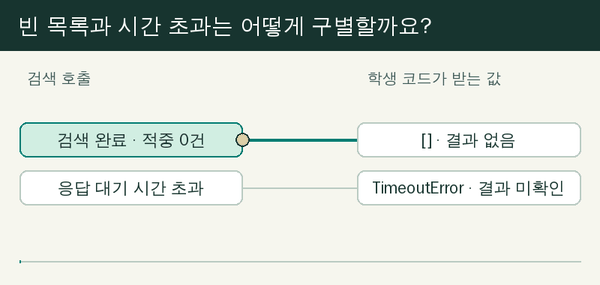

조회가 끝났을 때의 빈 목록과 완료되지 못한 검색은 서로 다른 관측입니다. 한쪽에서만 검색 결과가 0건이라는 결론을 낼 수 있습니다.
<!-- /lesson-visual visual-evidence -->


### 셀 01 · 빈 문서 목록의 종료 조건

가상 도서관의 주차 질문을 로컬 자료에서 찾습니다.


In [1]:
records = [{'id': 'library-1',
  'text': '도서 대출 기간은 14일입니다.',
  'source': '가상 도서관 이용 안내',
  'page': 1},
 {'id': 'library-2',
  'text': '도서관은 월요일에 휴관합니다.',
  'source': '가상 도서관 이용 안내',
  'page': 2},
 {'id': 'library-3',
  'text': '무인 반납함은 24시간 이용할 수 있습니다.',
  'source': '가상 도서관 이용 안내',
  'page': 3}]
terms = ("대출", "휴관", "반납")

def retrieve(question, k=1):
    query = [int(term in question) for term in terms]
    if not any(query):
        return []
    def distance(row):
        vector = [int(term in row["text"]) for term in terms]
        return sum((a-b)**2 for a, b in zip(query, vector)), row["id"]
    return sorted(records, key=distance)[:k]

found = retrieve('주차 요금은?')
print(found)

[]


빈 목록이 돌아왔으므로 화면에는 자료에서 확인할 수 없다고 씁니다. 원문에 없는 가격을 모델에게 추측시키지 않습니다.


### 정상 반환과 예외를 나누는 기준

<p>주차 질문은 검색을 마친 뒤 빈 리스트를 돌려줍니다. 검색 시간이 초과되면 함수는 리스트를 반환하기 전에 멈춥니다. 두 경우를 모두 근거 없음으로 처리하면 검색 서비스를 복구해야 하는 순간을 놓칩니다.</p>


### 검색 시간이 초과되면 리스트 대신 except로 이동합니다

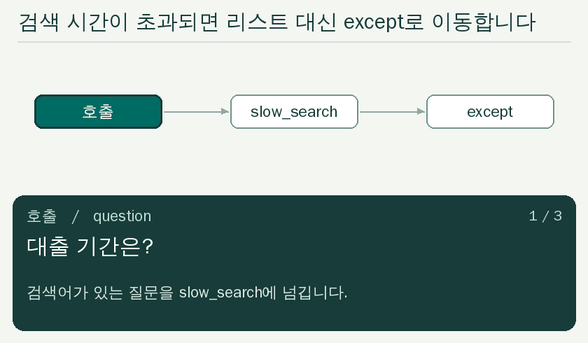

여기서는 Python 함수와 예외 처리문의 실행 위치를 따릅니다. 앞 셀의 정상 빈 리스트와 달리 slow_search에서 돌려받은 결과는 없습니다.


### 셀 02 · 검색 시간 초과 처리

시간 초과만 일으키는 함수로 장애 경로 한 곳을 재현합니다.

이 셀에서 직접 관찰할 것은 TimeoutError입니다. 검색기가 응답하지 않았으므로 문서가 없었다고 판단할 수 없습니다. 서비스로 제공할 때에는 오류를 기록하고 결과를 result=None으로 남길 수 있습니다.


In [2]:
def slow_search(question):
    raise TimeoutError('검색 시간이 초과되었습니다.')

try:
    slow_search('대출 기간은?')
except TimeoutError as error:
    print(type(error).__name__, str(error))

TimeoutError 검색 시간이 초과되었습니다.


TimeoutError가 출력됩니다. 이때는 검색 성공·빈 결과로 집계하지 않습니다. 재시도를 안내하고 결과 필드는 None으로 남깁니다.


### TimeoutError가 전달되는 위치

<p>slow_search는 대출 질문을 받아도 자료를 돌려주지 못합니다. 실행은 except TimeoutError로 이동합니다. 이 셀이 출력하는 것은 예외 이름과 메시지입니다. 재검색이나 답변 생성은 이 코드에서 실행되지 않습니다.</p>


## 검색된 문서 ID로 인용 검증

검색은 성공해도 답변 끝의 ID가 엉뚱할 수 있습니다. 근거 목록과 인용을 먼저 맞추고, 다음으로 그 문장에 적힌 내용까지 원문과 읽어 봅니다.


### 과제 03 · 반환 문서와 인용 ID 대조

대출 질문에서 가져온 문서 목록에 답안의 인용 library-2가 있는지 확인하세요. 참 또는 거짓으로 출력합니다.


In [3]:
found = retrieve('대출 기간은?')
cited = 'library-2'
# retrieved_ids를 만들고 cited가 포함되는지 확인하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>found = retrieve(&#x27;대출 기간은?&#x27;)
cited = &#x27;library-2&#x27;
retrieved_ids = {doc[&#x27;id&#x27;] for doc in found}
print(cited in retrieved_ids)</code></pre>
<p>실행 결과</p><pre><code>False</code></pre>
<p>False입니다. 찾은 문서는 library-1이므로 이 응답은 invalid_citation으로 분리합니다. 올바른 ID를 달아도 ‘999일’처럼 원문과 다른 답이 가능해 문장 대조가 남습니다.</p>
</details>


### 이번 요청에서 받은 문서 ID 집합

<p>대출 질문으로 찾은 레코드에서 id를 하나씩 꺼내 집합을 만듭니다. 답변의 인용 ID는 이번 집합과 대조해야 합니다. 도서관 자료 전체에 존재하는 ID라도 이번에 검색하지 않은 문서를 가리킬 수 있습니다.</p>


### ID 대조 다음에 확인할 문장

<p>인용 ID가 일치하면 해당 문서가 검색되었다는 사실을 확인할 수 있습니다. 답변이 대출 기간을 999일이라고 썼다면 올바른 ID가 붙어 있어도 원문의 14일과 어긋납니다. 마지막에는 답변과 해당 문장의 뜻을 대조하세요.</p>


### 이번 검색에서 나온 ID만 인용 대조에 사용합니다

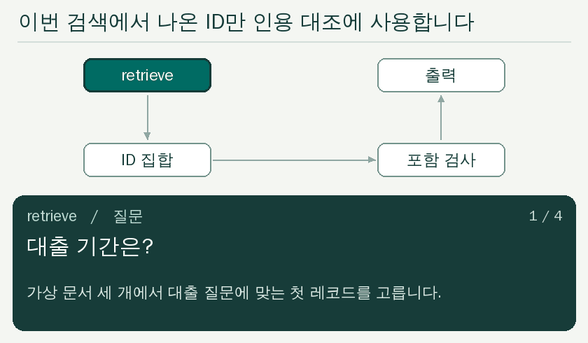

이 그림은 파이썬 집합 검사 순서입니다. 라이브러리에 존재하는 문서라도 이번 요청에서 반환하지 않은 ID이면 포함 검사 결과가 달라집니다.


## 돌아보기

사용자가 ‘자료를 더 주어야 할 때’와 ‘잠시 뒤 다시 물어야 할 때’를 구분하는 안내를 한 문장씩 써 보세요.
